# 10. Transaction – Quantity/Basket theo Label

## Câu hỏi

- Tổng quantity lớn có liên quan future purchase không?
- Basket lớn/nhỏ có phân phối khác nhau giữa hai label không?
- Basket đa dạng sản phẩm có liên quan propensity không?
- Khách mua nhiều loại product trong lịch sử có dễ quay lại không?

Mọi feature chỉ dùng giao dịch trong `[cutoff-90, cutoff-1]`.

In [5]:
%load_ext autoreload
%autoreload 2

from pathlib import Path

import matplotlib.pyplot as plt

from propensity.eda.transaction_quantity_basket_label import (
    load_transaction_quantity_basket_report,
)
from propensity.eda.product_category_label import (
    load_product_category_label_report,
)
from propensity.eda.transaction_quantity_basket_plots import (
    plot_department_breadth_boxplot,
    plot_quantity_basket_boxplots,
)


Failed to reload module 'propensity.overview.models' from file 'V:\Propensity_VSF\src\propensity\overview\models.py'
Traceback (most recent call last):
  File "v:\Propensity_VSF\.venv\Lib\site-packages\IPython\extensions\autoreload.py", line 326, in check
    superreload(m, reload, self.old_objects)
  File "v:\Propensity_VSF\.venv\Lib\site-packages\IPython\extensions\autoreload.py", line 621, in superreload
    update_generic(old_obj, new_obj)
  File "v:\Propensity_VSF\.venv\Lib\site-packages\IPython\extensions\autoreload.py", line 455, in update_generic
    update(a, b)
  File "v:\Propensity_VSF\.venv\Lib\site-packages\IPython\extensions\autoreload.py", line 407, in update_class
    if update_generic(old_obj, new_obj):
       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "v:\Propensity_VSF\.venv\Lib\site-packages\IPython\extensions\autoreload.py", line 455, in update_generic
    update(a, b)
  File "v:\Propensity_VSF\.venv\Lib\site-packages\IPython\extensions\autoreload.py", line 367, in up

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


[autoreload of propensity.overview.models failed: Traceback (most recent call last):
  File "v:\Propensity_VSF\.venv\Lib\site-packages\IPython\extensions\autoreload.py", line 326, in check
    superreload(m, reload, self.old_objects)
  File "v:\Propensity_VSF\.venv\Lib\site-packages\IPython\extensions\autoreload.py", line 621, in superreload
    update_generic(old_obj, new_obj)
  File "v:\Propensity_VSF\.venv\Lib\site-packages\IPython\extensions\autoreload.py", line 455, in update_generic
    update(a, b)
  File "v:\Propensity_VSF\.venv\Lib\site-packages\IPython\extensions\autoreload.py", line 407, in update_class
    if update_generic(old_obj, new_obj):
       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "v:\Propensity_VSF\.venv\Lib\site-packages\IPython\extensions\autoreload.py", line 455, in update_generic
    update(a, b)
  File "v:\Propensity_VSF\.venv\Lib\site-packages\IPython\extensions\autoreload.py", line 367, in update_function
    setattr(old, name, getattr(new, name))
ValueError

## 1. Build leakage-safe quantity và basket features

In [6]:
project_root = Path.cwd().resolve()
if project_root.name == "notebooks":
    project_root = project_root.parent

label_path = project_root / "data" / "processed" / "purchase_propensity_t90_h7_step7" / "household_cutoff_labels.parquet"
transaction_path = project_root / "data" / "raw" / "Dunnhumby" / "transaction_data.csv"

report = load_transaction_quantity_basket_report(
    label_path,
    transaction_path,
    observation_days=90,
)


## 2. Định nghĩa feature

| Feature | Định nghĩa trong 90 ngày trước cutoff |
|---|---|
| `total_quantity_90d` | Tổng `QUANTITY` của các product lines hợp lệ |
| `avg_items_per_basket_90d` | Tổng `QUANTITY` / số basket |
| `avg_unique_products_per_basket_90d` | Trung bình số `PRODUCT_ID` unique / basket |
| `unique_products_90d` | Tổng số `PRODUCT_ID` distinct trong toàn window |

In [7]:
report.summary_by_label

,feature,label,n_observations,missing_rate,p10,q1,median,q3,p90
0,total_quantity_90d,0,94821,0.000000,0.000000,11.000000,57.000000,207.000000,13821.000000
1,total_quantity_90d,1,107423,0.000000,44.000000,124.000000,380.000000,24289.000000,78109.000000
2,avg_items_per_basket_90d,0,80878,0.147045,3.500000,6.611111,13.769231,36.000000,1821.117857
3,avg_items_per_basket_90d,1,106384,0.009672,5.750000,10.333333,23.400000,1159.056993,2859.338065
4,avg_unique_products_per_basket_90d,0,80878,0.147045,2.500000,4.333333,8.000000,13.666667,21.000000
5,avg_unique_products_per_basket_90d,1,106384,0.009672,3.714286,5.773585,8.926378,13.391304,18.866667
6,unique_products_90d,0,94821,0.000000,0.000000,7.000000,33.000000,83.000000,149.000000
7,unique_products_90d,1,107423,0.000000,27.000000,63.000000,126.000000,209.000000,300.000000


## 3. Box plot theo label

Whisker dùng quy tắc 1,5 × IQR. Outlier được hiển thị bằng marker nhỏ với alpha thấp để hạn chế chồng lấn.

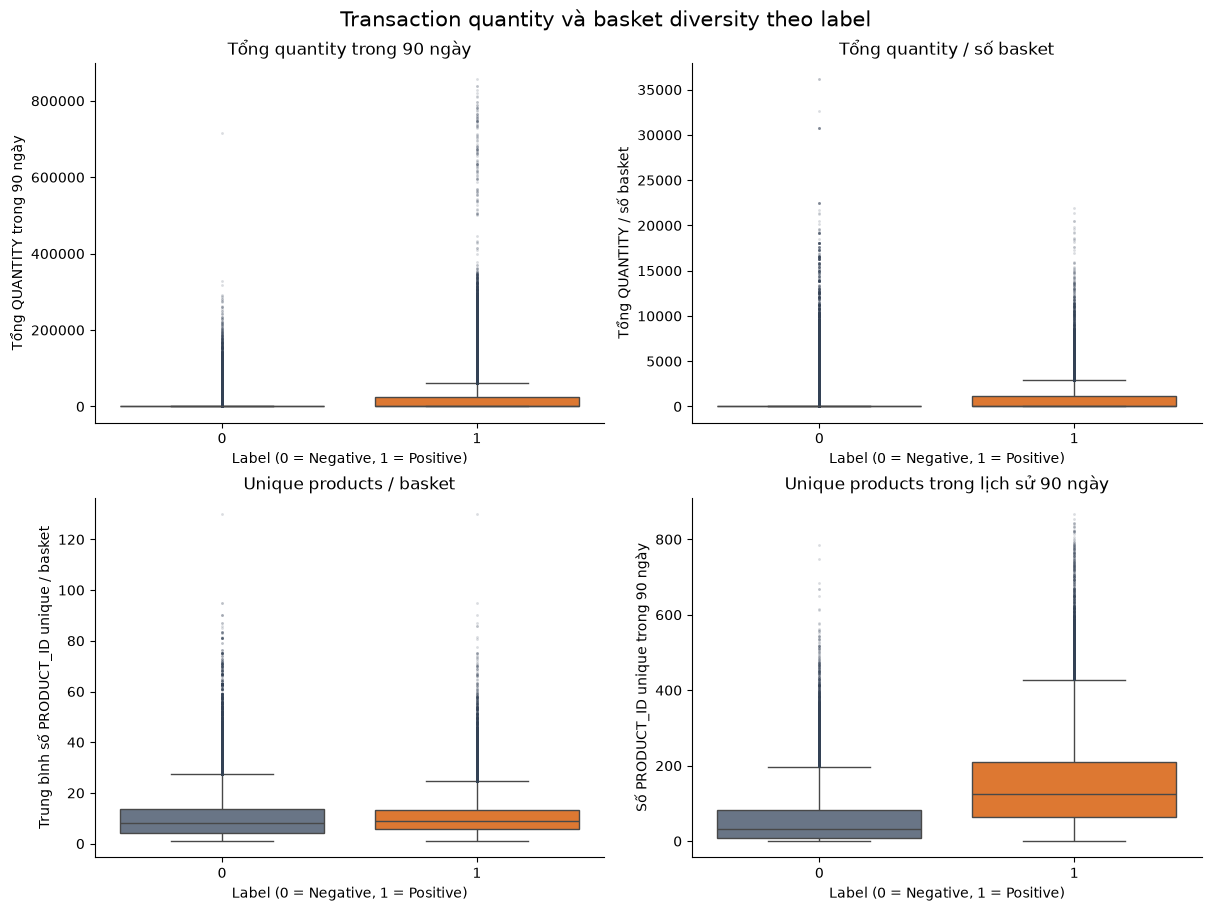

In [8]:
figure = plot_quantity_basket_boxplots(report.feature_panel)
plt.show()

## Lưu ý diễn giải

- Quantity và unique products/basket được tính sau khi đưa dữ liệu về basket grain.
- Giao dịch ngày cutoff không được dùng làm feature.
- Household không có activity trong window có total quantity và unique products bằng 0; basket averages là null vì không xác định.
- Box plot thể hiện association, không chứng minh basket size hoặc diversity gây ra label dương.
- Parquet label cần được tạo lại sau khi target window đổi thành `[cutoff, cutoff+6]`.

## 4. Department breadth theo label

`n_departments_90d` là số department unique household từng mua trong `[cutoff-90, cutoff-1]`.

In [9]:
product_path = (
    project_root / "data" / "raw" / "Dunnhumby" / "product.csv"
)
department_report = load_product_category_label_report(
    label_path,
    transaction_path,
    product_path,
    observation_days=90,
)

In [10]:
department_report.breadth_summary_by_label.loc[
    lambda frame: frame["feature"] == "n_departments_90d"
]

,feature,label,n_observations,q1,median,q3
0,n_departments_90d,0,94821,2.0,5.0,7.0
1,n_departments_90d,1,107423,6.0,8.0,10.0


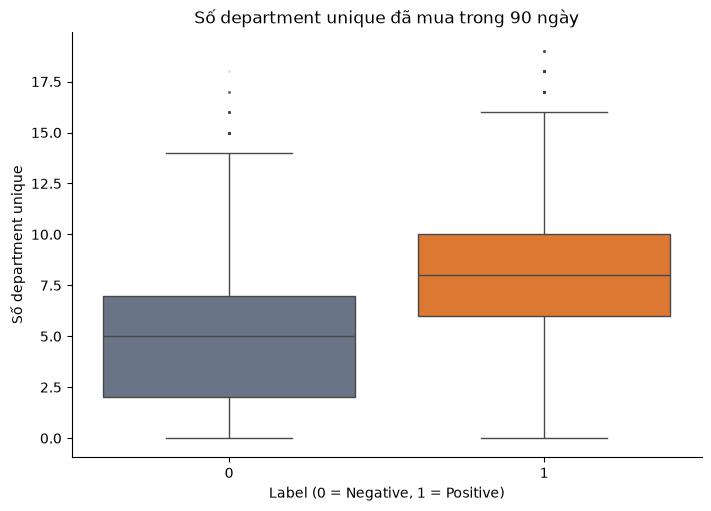

In [11]:
department_breadth_figure = plot_department_breadth_boxplot(
    department_report.feature_panel
)
plt.show()